# Aula 09 — Big Data: Apache Spark e dados reais de bicicletas

## Structured Streaming com a API pública Citi Bike

Nesta aula, vamos construir um pequeno sistema que:

1. Consulta **dados reais** de estações de bicicletas em Nova York.
2. Realiza **novas consultas automaticamente**, a cada intervalo configurado.
3. Salva cada consulta como um arquivo JSON.
4. Usa o **Spark Structured Streaming** para processar os arquivos à medida que chegam.
5. Exibe indicadores, gráficos e consultas SQL para acompanhar as mudanças.

**API Citi Bike → coletor Python (a cada X segundos) → novos arquivos JSON → Spark (`readStream`) → tabela e gráficos**

## 1. Instalação e importação das bibliotecas

Antes de iniciar, precisamos preparar as ferramentas:

- **`requests`**: faz consultas HTTP à API, como se nosso programa acessasse um endereço da internet.
- **`pyspark`**: permite criar uma sessão Spark e processar dados que chegam continuamente.
- **`matplotlib`**: gera gráficos.
- **`threading`**: permite manter a coleta em uma tarefa separada, enquanto continuamos usando outras células do notebook.

Execute as próximas células **uma vez, de cima para baixo**.

In [1]:
%pip -q install pyspark requests matplotlib pandas

In [2]:
# Bibliotecas para acessar a API, salvar arquivos e controlar a coleta periódica.
import json
import os
import shutil
import threading
import time
from datetime import datetime, timezone

# Bibliotecas para requisitar dados e apresentar gráficos e tabelas.
import requests
import matplotlib.pyplot as plt
from IPython.display import display

# Componentes do Apache Spark e tipos das colunas.
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType

## 2. Conhecendo a API e os dados recebidos

Uma **API** é um meio pelo qual um programa solicita dados de outro sistema. A Citi Bike publica informações de suas estações em arquivos JSON acessíveis pela internet.

Vamos usar dois endereços:

| Endereço | O que informa? | Exemplo |
|---|---|---|
| `station_information.json` | Cadastro das estações | Nome e identificador da estação |
| `station_status.json` | Situação atual das estações | Bicicletas e vagas disponíveis |

Uma estação pode informar, por exemplo, **5 bicicletas disponíveis e 3 vagas livres**. Esses números podem mudar depois que uma pessoa utiliza o serviço.

Na próxima célula, faremos **uma consulta de teste** para conhecer a estrutura dos dados. A coleta automática será configurada mais adiante.

In [3]:
# Endereços públicos da API da Citi Bike.
URL_STATUS = "https://gbfs.citibikenyc.com/gbfs/en/station_status.json"
URL_INFO = "https://gbfs.citibikenyc.com/gbfs/en/station_information.json"

# Consulta a situação atual das estações.
resposta = requests.get(URL_STATUS, timeout=30)
resposta.raise_for_status()
dados = resposta.json()["data"]["stations"]

# Exibe quantas estações foram encontradas e um exemplo do JSON retornado.
print("Estações encontradas:", len(dados))
print("Exemplo de registro recebido da API:")
print(json.dumps(dados[0], indent=2, ensure_ascii=False)[:1200])

Estações encontradas: 2519
Exemplo de registro recebido da API:
{
  "station_id": "3eb10c63-ea4c-4161-b07d-a29034f7367a",
  "num_bikes_available": 0,
  "num_bikes_disabled": 0,
  "num_docks_available": 0,
  "num_docks_disabled": 0,
  "is_installed": 0,
  "is_renting": 0,
  "is_returning": 0,
  "last_reported": 86400,
  "legacy_id": "3950",
  "num_ebikes_available": 0,
  "eightd_has_available_keys": false
}


## 3. Criando a sessão Spark

O **Apache Spark** é um mecanismo de processamento de dados. Ele também pode trabalhar com dados que chegam continuamente por meio do **Structured Streaming**.

A `SparkSession` é a porta de entrada para utilizar o Spark em Python.

In [4]:
# Cria a sessão que será utilizada por todas as próximas células.
spark = SparkSession.builder.appName("Aula09_Bicicletas").getOrCreate()

# Reduz as mensagens técnicas exibidas no notebook.
spark.sparkContext.setLogLevel("ERROR")

print("Spark iniciado. Versão:", spark.version)

Spark iniciado. Versão: 4.0.4


## 4. Preparando as pastas do streaming

O Spark precisa saber **onde procurar os arquivos novos**. Vamos criar três pastas:

- **`entrada`**: contém os arquivos JSON que o Spark deverá processar.
- **`temporarios`**: recebe o arquivo enquanto o Python ainda está escrevendo. Depois ele é movido para `entrada` já completo.
- **`checkpoint`**: guarda informações de progresso do processamento, usadas para acompanhar quais arquivos foram processados.

**Atenção:** ao executar a próxima célula, os arquivos dessa demonstração serão apagados para começar uma nova atividade. Não a execute enquanto a coleta automática estiver funcionando.

In [5]:
# Pasta principal da atividade no Google Colab.
PASTA_BASE = "/content/bicicletas_stream"
PASTA_ENTRADA = f"{PASTA_BASE}/entrada"
PASTA_TEMPORARIOS = f"{PASTA_BASE}/temporarios"
PASTA_CHECKPOINT = f"{PASTA_BASE}/checkpoint"

# Limpa apenas os arquivos de uma execução anterior da atividade.
shutil.rmtree(PASTA_BASE, ignore_errors=True)

# Cria as pastas necessárias para a nova execução.
os.makedirs(PASTA_ENTRADA, exist_ok=True)
os.makedirs(PASTA_TEMPORARIOS, exist_ok=True)

print("Pasta acompanhada pelo Spark:", PASTA_ENTRADA)

Pasta acompanhada pelo Spark: /content/bicicletas_stream/entrada


## 5. Definindo os campos que o Spark vai ler

Cada consulta à API produz uma **fotografia** da disponibilidade das estações naquele instante. Vamos salvar um arquivo com **uma linha JSON por estação**.

Exemplo simplificado de uma linha:

```json
{"coleta": 1, "estacao": "123", "nome": "Estação Central", "bicicletas": 5, "vagas": 3}
```

Chamamos de **schema (esquema)** a definição das colunas e seus tipos: texto, número inteiro etc. No Structured Streaming, informamos esse esquema antes da leitura.

A diferença entre os dois comandos é:

- **`spark.read`**: lê os arquivos disponíveis naquele momento.
- **`spark.readStream`**: configura uma leitura contínua de **novos arquivos** que chegarem à pasta.

> `readStream` ainda **não inicia** a execução: por enquanto estamos apenas definindo o fluxo.

In [6]:
# Define o formato das linhas JSON gravadas pelo coletor.
esquema = StructType([
    StructField("coleta", IntegerType()),
    StructField("instante", StringType()),
    StructField("estacao", StringType()),
    StructField("nome", StringType()),
    StructField("bicicletas", IntegerType()),
    StructField("vagas", IntegerType())
])

# Configura a leitura contínua dos novos arquivos JSON.
df_stream = spark.readStream.schema(esquema).json(PASTA_ENTRADA)

# Confirma que não se trata de um DataFrame de leitura única.
print("É um DataFrame de streaming?", df_stream.isStreaming)

É um DataFrame de streaming? True


## 6. Transformando os dados recebidos

Queremos saber se cada estação está em uma destas situações:

- **Sem bicicletas:** não há bicicletas disponíveis para retirada.
- **Sem vagas:** não há vagas disponíveis para devolução.
- **Normal:** há pelo menos uma bicicleta e uma vaga.

Vamos utilizar `withColumn()` para criar a coluna **`situacao`** e `when()` para definir as regras. A mesma transformação será aplicada a cada novo arquivo.

> Se uma estação tiver **zero bicicletas e zero vagas**, ela aparecerá como **Sem bicicletas**, pois essa condição é testada primeiro.

In [7]:
# Cria uma coluna de classificação sem alterar os dados originais.
situacao_stream = df_stream.withColumn(
    "situacao",
    F.when(F.col("bicicletas") == 0, "Sem bicicletas")
     .when(F.col("vagas") == 0, "Sem vagas")
     .otherwise("Normal")
)

# Mostra a estrutura das colunas que serão processadas.
situacao_stream.printSchema()

root
 |-- coleta: integer (nullable = true)
 |-- instante: string (nullable = true)
 |-- estacao: string (nullable = true)
 |-- nome: string (nullable = true)
 |-- bicicletas: integer (nullable = true)
 |-- vagas: integer (nullable = true)
 |-- situacao: string (nullable = false)



## 7. Iniciando o Spark Structured Streaming

Agora vamos executar o fluxo com **`writeStream`**.

- **`format("memory")`**: guarda os resultados em uma tabela temporária na memória do Spark.
- **`queryName("bicicletas")`**: dá um nome à tabela para podermos fazer consultas com SQL.
- **`outputMode("append")`**: acrescenta novos registros sem apagar os anteriores.
- **`trigger(processingTime="5 seconds")`**: faz o Spark verificar periodicamente se chegaram arquivos novos.
- **`start()`**: inicia a consulta contínua.

Como cada arquivo contém o estado completo das estações, precisamos selecionar a **última coleta** ao calcular a disponibilidade atual. Somar todas as coletas significaria contar as mesmas estações repetidamente.

In [8]:
# Inicia o processamento contínuo com os registros salvos na pasta entrada.
consulta = (
    situacao_stream.writeStream
    .format("memory")
    .queryName("bicicletas")
    .outputMode("append")
    .option("checkpointLocation", PASTA_CHECKPOINT)
    .trigger(processingTime="5 seconds")
    .start()
)

print("Structured Streaming ativo?", consulta.isActive)

Structured Streaming ativo? True


## 8. Criando a coleta automática em segundo plano

Até aqui, o Spark está acompanhando a pasta, mas **ainda não há um programa trazendo os dados da API**.

Agora criaremos um **coletor Python** que funciona de maneira independente das próximas células:

1. Acessa a API da Citi Bike.
2. Lê a quantidade de bicicletas e vagas em cada estação.
3. Cria um arquivo JSON completo, identificado pelo número da coleta.
4. Espera **`INTERVALO_SEGUNDOS`** e repete o processo.

Para isso, utilizamos uma **thread**, isto é, uma tarefa do Python que pode continuar executando enquanto usamos outras células.

> A coleta roda em segundo plano **apenas enquanto o ambiente Python do Colab estiver ativo**. Ela não continuará executando após o encerramento ou a desconexão do ambiente. Não é um serviço permanente externo.

In [9]:
# Quantos segundos esperar entre uma consulta e a próxima.
INTERVALO_SEGUNDOS = 60

# Busca os nomes das estações uma única vez para facilitar a leitura dos relatórios.
resposta_info = requests.get(URL_INFO, timeout=30)
resposta_info.raise_for_status()
nomes = {
    str(e["station_id"]): e.get("name", str(e["station_id"]))
    for e in resposta_info.json()["data"]["stations"]
}

# Evento usado para solicitar a parada da tarefa em segundo plano.
parar_coleta = threading.Event()

# Contador que identifica os arquivos criados em sequência.
numero_coleta = 0


def coletar():
    global numero_coleta

    # Consulta o estado atual das estações na API pública.
    resposta = requests.get(URL_STATUS, timeout=30)
    resposta.raise_for_status()
    estacoes = resposta.json()["data"]["stations"]

    # Registra a hora da consulta e o número do novo lote.
    proxima_coleta = numero_coleta + 1
    instante = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S")

    # Prepara um arquivo JSON: cada linha representa uma estação.
    arquivo_nome = f"coleta_{proxima_coleta:05d}.json"
    caminho_temporario = os.path.join(PASTA_TEMPORARIOS, arquivo_nome)
    caminho_final = os.path.join(PASTA_ENTRADA, arquivo_nome)

    with open(caminho_temporario, "w", encoding="utf-8") as arquivo:
        for estacao in estacoes:
            codigo = str(estacao["station_id"])
            registro = {
                "coleta": proxima_coleta,
                "instante": instante,
                "estacao": codigo,
                "nome": nomes.get(codigo, codigo),
                "bicicletas": int(estacao.get("num_bikes_available", 0)),
                "vagas": int(estacao.get("num_docks_available", 0))
            }
            arquivo.write(json.dumps(registro, ensure_ascii=False) + "\n")

    # Move o arquivo pronto para a pasta acompanhada pelo Spark.
    os.replace(caminho_temporario, caminho_final)
    numero_coleta = proxima_coleta
    print(f"Coleta {numero_coleta}: {len(estacoes)} estações às {instante} (UTC)")


def executar_coleta_automatica():
    # Enquanto não houver pedido de parada, realiza uma consulta por intervalo.
    while not parar_coleta.is_set():
        try:
            coletar()
        except (requests.RequestException, ValueError, OSError, KeyError) as erro:
            # Uma falha temporária na API não encerra a tarefa.
            print("Falha na coleta:", erro)

        # Espera o intervalo definido, mas permite interromper imediatamente.
        if parar_coleta.wait(INTERVALO_SEGUNDOS):
            break

In [10]:
# Inicia a coleta automática uma única vez, sem bloquear o notebook.
if "tarefa_coleta" not in globals() or not tarefa_coleta.is_alive():
    parar_coleta.clear()
    tarefa_coleta = threading.Thread(target=executar_coleta_automatica, daemon=True)
    tarefa_coleta.start()

print("Coleta em segundo plano?", tarefa_coleta.is_alive())
print("Intervalo entre consultas:", INTERVALO_SEGUNDOS, "segundos")
print("O Spark continuará processando os novos arquivos automaticamente.")

Coleta em segundo plano? True
Intervalo entre consultas: 60 segundos
O Spark continuará processando os novos arquivos automaticamente.


## 9. Consultando os indicadores e construindo os gráficos

A coleta e o Spark já estão funcionando em segundo plano. **Não é necessário chamar `coletar()` nem criar novos arquivos manualmente.**

A função abaixo encontra a **última coleta já processado pelo Spark** e usa somente esse instante para exibir:

- Total de estações monitoradas.
- Bicicletas e vagas disponíveis.
- Estações sem bicicletas ou sem vagas.
- Gráfico da situação das estações.
- As dez estações com mais bicicletas.

**Como observar mudanças:** execute `mostrar_resultados()` agora e repita a mesma célula depois de um ou dois minutos. A tarefa continuará coletando dados mesmo entre as execuções.

> Se aparecer a mensagem de que ainda não há dados, aguarde a primeira consulta à API e o primeiro micro-lote do Spark (alguns segundos) e execute novamente.

In [ ]:
def mostrar_resultados():
    # Obtém a coleta mais recente que já foi processada pelo Spark.
    ultima_coleta = spark.sql("SELECT MAX(coleta) AS numero FROM bicicletas").first()["numero"]

    if ultima_coleta is None:
        print("Ainda não há dados processados. Execute esta célula novamente em alguns segundos.")
        return

    # Seleciona apenas o retrato atual das estações.
    atual = spark.sql(f"SELECT * FROM bicicletas WHERE coleta = {ultima_coleta}")

    # Calcula os indicadores considerando apenas a última coleta.
    # A variável "atual" já contém somente os registros dessa coleta.

    resumo = atual.agg(

        # Conta o número total de registros (estações) encontrados na coleta.
        F.count("*").alias("Estacoes"),

        # Soma a quantidade de bicicletas disponíveis em todas as estações.
        F.sum("bicicletas").alias("Bicicletas disponiveis"),

        # Soma a quantidade de vagas disponíveis em todas as estações.
        F.sum("vagas").alias("Vagas disponiveis"),

        # Conta quantas estações estão SEM bicicletas.
        # F.col("bicicletas") == 0 verifica se a estação tem zero bicicletas.
        # F.when(..., 1) retorna 1 quando essa condição é verdadeira.
        # .otherwise(0) retorna 0 quando a condição é falsa.
        # F.sum() soma esses valores, contando as estações sem bicicletas.
        F.sum(
            F.when(F.col("bicicletas") == 0, 1).otherwise(0)
        ).alias("Sem bicicletas"),

        # Conta quantas estações estão SEM vagas disponíveis.
        # Se vagas == 0, retorna 1 (estação sem vagas).
        # Caso contrário, retorna 0 (estação com vagas).
        # F.sum() contabiliza quantas estações receberam o valor 1.
        F.sum(
            F.when(F.col("vagas") == 0, 1).otherwise(0)
        ).alias("Sem vagas")

    )


    print(f"RESULTADOS DA COLETA {ultima_coleta}")
    print("Hora da consulta (UTC):", atual.select("instante").first()["instante"])
    display(resumo.toPandas())

    # Mostra quantas estações estão em cada situação.
    contagem = atual.groupBy("situacao").count().toPandas()
    contagem.plot.bar(x="situacao", y="count", legend=False, figsize=(7, 3))
    plt.title("Situação atual das estações")
    plt.xlabel("")
    plt.ylabel("Quantidade de estações")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Exibe as dez estações com mais bicicletas disponíveis.
    top = atual.orderBy(F.desc("bicicletas")).limit(10).toPandas()
    top.sort_values("bicicletas").plot.barh(
        x="nome", y="bicicletas", legend=False, figsize=(8, 4)
    )
    plt.title("10 estações com mais bicicletas disponíveis")
    plt.xlabel("Bicicletas disponíveis")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

RESULTADOS DA COLETA 4
Hora da consulta (UTC): 2026-10-20 17:12:16


,Estacoes,Bicicletas disponiveis,Vagas disponiveis,Sem bicicletas,Sem vagas
0,2519,35055,31908,246,261


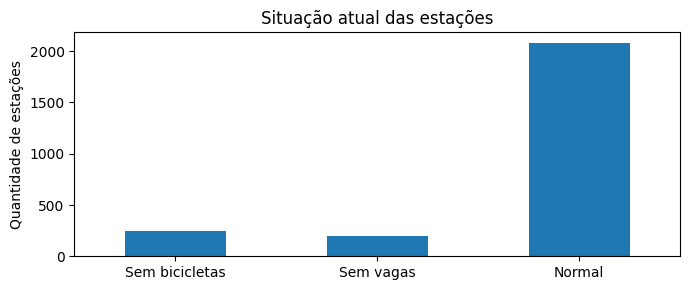

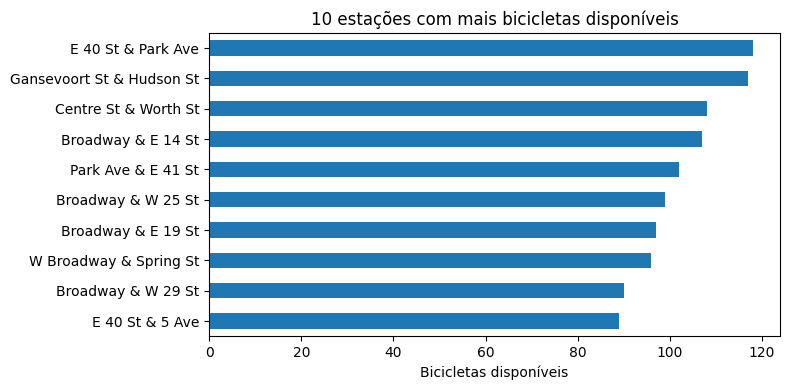

In [26]:
# Exibe a situação mais recente disponível na tabela Spark.
# Execute novamente depois de algum tempo para atualizar os gráficos.
mostrar_resultados()

## 10. Comparando as coletas feitas automaticamente

O coletor salva vários arquivos ao longo do tempo. Cada arquivo corresponde a **uma nova observação do sistema**, identificada pelo campo `coleta`.

Vamos utilizar `GROUP BY` para calcular os totais de cada observação e construir um gráfico de evolução.

**Exemplo:** se na coleta 1 existem 10 bicicletas em uma estação e na coleta 2 existem 8, a disponibilidade diminuiu em 2. Isso **não significa necessariamente duas retiradas**, porque também podem ter ocorrido devoluções e movimentação de bicicletas pela empresa.

,coleta,instante,estacoes,bicicletas,vagas
0,1,2026-10-20 17:09:16,2519,35043,31871
1,2,2026-10-20 17:10:16,2519,35018,31901
2,3,2026-10-20 17:11:16,2519,35037,31918
3,4,2026-10-20 17:12:16,2519,35055,31908


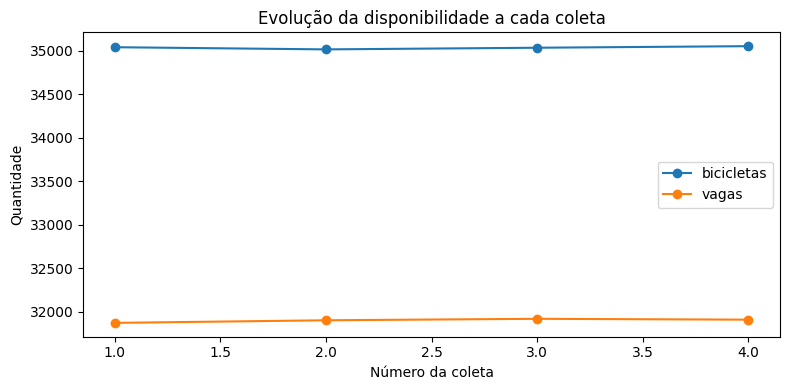

In [27]:
# Agrupa os registros por coleta para comparar diferentes instantes.
evolucao = spark.sql("""
    SELECT coleta,
           MIN(instante) AS instante,
           COUNT(*) AS estacoes,
           SUM(bicicletas) AS bicicletas,
           SUM(vagas) AS vagas
    FROM bicicletas
    GROUP BY coleta
    ORDER BY coleta
""")

# Transforma apenas o resumo (poucas linhas) em Pandas para criar o gráfico.
tabela_evolucao = evolucao.toPandas()
display(tabela_evolucao)

if len(tabela_evolucao) >= 2:
    tabela_evolucao.plot(
        x="coleta", y=["bicicletas", "vagas"], marker="o", figsize=(8, 4)
    )
    plt.title("Evolução da disponibilidade a cada coleta")
    plt.xlabel("Número da coleta")
    plt.ylabel("Quantidade")
    plt.tight_layout()
    plt.show()
else:
    print("Aguarde ao menos duas coletas para comparar os resultados.")

## 11. Consultando a última coleta com Spark SQL

O Spark permite executar **consultas SQL** sobre a tabela temporária `bicicletas`, como faríamos em um banco de dados.

Queremos responder: **quais são as dez estações com menos bicicletas disponíveis no momento?**

A subconsulta `SELECT MAX(coleta)` identifica automaticamente o último retrato processado.

In [28]:
# Consulta SQL que sempre utiliza a coleta mais recente.
spark.sql("""
    SELECT nome, bicicletas, vagas, situacao
    FROM bicicletas
    WHERE coleta = (SELECT MAX(coleta) FROM bicicletas)
    ORDER BY bicicletas, nome
    LIMIT 10
""").show(truncate=False)

+-----------------+----------+-----+--------------+
|nome             |bicicletas|vagas|situacao      |
+-----------------+----------+-----+--------------+
|1 Pl & Clinton St|0         |33   |Sem bicicletas|
|11 Ave & W 27 St |0         |0    |Sem bicicletas|
|11 Ave & W 30 St |0         |0    |Sem bicicletas|
|18 St & 27 Ave   |0         |0    |Sem bicicletas|
|2 Ave & 32 St    |0         |0    |Sem bicicletas|
|2 Ave & 36 St    |0         |0    |Sem bicicletas|
|21 St & 20 Ave   |0         |0    |Sem bicicletas|
|21 St & 23 Ave   |0         |9    |Sem bicicletas|
|23 St & 31 Ave   |0         |19   |Sem bicicletas|
|24 Ave & 26 St   |0         |16   |Sem bicicletas|
+-----------------+----------+-----+--------------+



## Encerrando a coleta e o Spark

Ao terminar a aula, é importante desligar as tarefas:

1. **`parar_coleta.set()`** solicita que a coleta automática termine.
2. **`tarefa_coleta.join()`** aguarda sua finalização (se houver uma consulta à API em andamento, ela pode terminar antes da parada).
3. **`consulta.stop()`** interrompe o Structured Streaming.
4. **`spark.stop()`** encerra a sessão Spark.

**Execute a próxima célula somente quando terminar a análise.** Depois disso, as consultas e os gráficos não funcionarão até que a sessão e o fluxo sejam iniciados novamente.

In [ ]:
# Solicita a parada do coletor de dados.
parar_coleta.set()

# Aguarda o término da tarefa Python antes de encerrar o Spark.
tarefa_coleta.join(timeout=35)

# Para a leitura contínua e libera os recursos computacionais.
consulta.stop()
spark.stop()

print("Coleta em segundo plano ativa?", tarefa_coleta.is_alive())
print("Structured Streaming ativo?", consulta.isActive)